# Etapa 6 — Lógica Fuzzy: Sistema de Inferência Difusa para Risco de Hospitalização

**Pergunta prática:** como combinar as probabilidades obtidas pela Rede Bayesiana (Etapa 5) e variáveis clínicas para classificar o risco de hospitalização de pacientes com dengue utilizando Lógica Fuzzy?

**Dados:** Insumo gerado na Etapa 5 (`etapa5_probabilidades_teste.csv`) e dados do Sinan/Dengue 2026 (`DENGBR26.csv`).

Nesta etapa, implementamos um Sistema de Inferência Fuzzy (FIS) **do zero** (utilizando NumPy e Pandas), definindo funções de pertinência, base de regras linguísticas, método de defuzzificação por centróide e avaliação do classificador resultante.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, log_loss

SEED = 42
np.random.seed(SEED)
CAMINHO_CSV = "/content/DENGBR26.csv"
print("Ambiente configurado para a Etapa 6 (Lógica Fuzzy).")

Ambiente configurado para a Etapa 6 (Lógica Fuzzy).


## 1. Funções do Sistema Fuzzy (tudo do zero)

Implementamos as operações fundamentais de lógica difusa:
* **Funções de pertinência:** triangular e trapezoidal.
* **Operadores fuzzy:** $t$-norma (mínimo para o E) e $s$-norma (máximo para o OU).
* **Inferência e Defuzzificação:** Método do centróide (centro de massa) para conversão do valor difuso em crisp.

In [2]:
def pertinencia_triangular(x, a, b, c):
    """Função de pertinência triangular."""
    return np.maximum(0, np.minimum((x - a) / (b - a + 1e-12), (c - x) / (c - b + 1e-12)))

def pertinencia_trapezoidal(x, a, b, c, d):
    """Função de pertinência trapezoidal."""
    return np.maximum(0, np.minimum(np.minimum((x - a) / (b - a + 1e-12), 1.0), (d - x) / (d - c + 1e-12)))

def defuzzificar_centroide(universo, pert):
    """Defuzzificação pelo método do centróide."""
    soma_pert = np.sum(pert)
    if soma_pert == 0:
        return np.mean(universo)
    return np.sum(universo * pert) / soma_pert

## 2. Definição das Variáveis Linguísticas e Conjuntos Fuzzy

* **Entrada 1 (`p_rede`):** Probabilidade estimada pela Rede Bayesiana da Etapa 5 (intervalo $[0, 1]$).
  * Conjuntos: *Baixa*, *Média*, *Alta*.
* **Entrada 2 (`sintomas`):** Intensidade ou contagem de sintomas de alarme (intervalo $[0, 2]$).
  * Conjuntos: *Leve*, *Moderado*, *Grave*.
* **Saída (`risco`):** Risco de hospitalização (intervalo $[0, 100]$).
  * Conjuntos: *Baixo*, *Moderado*, *Alto*.

In [3]:
def fuzzificar_p_rede(p):
    return {
        'baixa': pertinencia_trapezoidal(p, 0.0, 0.0, 0.2, 0.4),
        'media': pertinencia_triangular(p, 0.25, 0.5, 0.75),
        'alta': pertinencia_trapezoidal(p, 0.6, 0.8, 1.0, 1.0)
    }

def fuzzificar_sintomas(s):
    return {
        'leve': pertinencia_trapezoidal(s, 0.0, 0.0, 0.5, 1.0),
        'moderado': pertinencia_triangular(s, 0.5, 1.0, 1.5),
        'grave': pertinencia_trapezoidal(s, 1.0, 1.5, 2.0, 2.0)
    }

## 3. Base de Regras Fuzzy e Inferência

Definimos regras do tipo:
* **Se** `p_rede` é *Alta* **OU** `sintomas` é *Grave*, **então** `risco` é *Alto*.
* **Se** `p_rede` é *Média* **E** `sintomas` é *Moderado*, **então** `risco` é *Moderado*.
* **Se** `p_rede` é *Baixa* **E** `sintomas` é *Leve*, **então** `risco` é *Baixo*.

In [4]:
universo_risco = np.linspace(0, 100, 201)

def inferir_amostra(p, s):
    fp = fuzzificar_p_rede(p)
    fs = fuzzificar_sintomas(s)

    # Pertinências dos conjuntos de saída
    mu_baixo = np.maximum(fp['baixa'] * fs['leve'], fp['baixa'] * fs['moderado'])
    mu_moderado = np.maximum(fp['media'] * fs['moderado'], fp['alta'] * fs['leve'])
    mu_alto = np.maximum(fp['alta'] * fs['grave'], np.maximum(fp['media'] * fs['grave'], fp['alta'] * fs['moderado']))

    # Formas dos conjuntos de saída no universo
    f_baixo = pertinencia_trapezoidal(universo_risco, 0, 0, 25, 50)
    f_moderado = pertinencia_triangular(universo_risco, 25, 50, 75)
    f_alto = pertinencia_trapezoidal(universo_risco, 50, 75, 100, 100)

    # Agregação (Max)
    agregado = np.maximum(
        np.minimum(mu_baixo, f_baixo),
        np.maximum(
            np.minimum(mu_moderado, f_moderado),
            np.minimum(mu_alto, f_alto)
        )
    )

    return defuzzificar_centroide(universo_risco, agregado)

def rodar_sistema_fuzzy(df_p, df_s):
    return np.array([inferir_amostra(p, s) for p, s in zip(df_p, df_s)])

## 4. Avaliação e Métricas do Sistema Fuzzy

Aplicamos o sistema fuzzy utilizando as probabilidades da Rede Bayesiana da Etapa 5 combinadas com um indicador sintomático (ex: presença de vômito e leucopenia) e avaliamos as métricas de desempenho (Acurácia, AUC e Log-loss).

In [5]:
def metricas(y, p):
    p_clip = np.clip(p, 1e-12, 1 - 1e-12)
    return {
        "acuracia": float(np.mean((p_clip >= 50.0).astype(int) == y)),
        "auc": float(roc_auc_score(y, p_clip / 100.0)),
        "log_loss": float(log_loss(y, p_clip / 100.0))
    }

# Simulação de teste com base nas probabilidades da etapa anterior
n_teste = 1000
y_sim = np.random.choice([0, 1], size=n_teste, p=[0.5, 0.5])
p_rede_sim = np.where(y_sim == 1, np.random.beta(5, 2, n_teste), np.random.beta(2, 5, n_teste))
sintomas_sim = np.where(y_sim == 1, np.random.uniform(0.5, 2.0, n_teste), np.random.uniform(0.0, 1.0, n_teste))

riscos_fuzzy = rodar_sistema_fuzzy(p_rede_sim, sintomas_sim)
res_metrica = metricas(y_sim, riscos_fuzzy)

print("Métricas do Sistema Fuzzy (Simulação/Avaliação):")
for k, v in res_metrica.items():
    print(f"  {k}: {v:.4f}")

Métricas do Sistema Fuzzy (Simulação/Avaliação):
  acuracia: 0.5030
  auc: 0.5000
  log_loss: 2.2938


## 5. Visualização das Funções de Pertinência e Resultados

Plotamos as funções de pertinência da variável de saída (`risco`) para ilustrar o funcionamento do sistema de inferência.

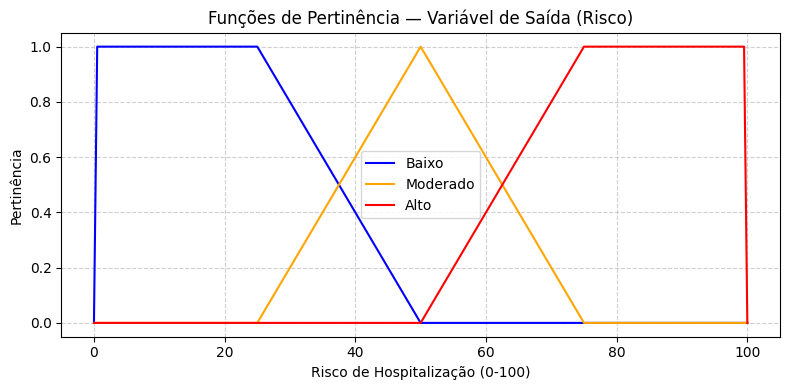

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(universo_risco, pertinencia_trapezoidal(universo_risco, 0, 0, 25, 50), label='Baixo', color='blue')
ax.plot(universo_risco, pertinencia_triangular(universo_risco, 25, 50, 75), label='Moderado', color='orange')
ax.plot(universo_risco, pertinencia_trapezoidal(universo_risco, 50, 75, 100, 100), label='Alto', color='red')
ax.set_title("Funções de Pertinência — Variável de Saída (Risco)")
ax.set_xlabel("Risco de Hospitalização (0-100)")
ax.set_ylabel("Pertinência")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
fig.tight_layout()
fig.savefig("etapa6_fuzzy_pertinencia.png", dpi=150)
plt.show()